# Mission 5 — Macroeconomic surprises and the repricing of policy expectations (Yasmine)

**Objective.** Measure how market-implied policy expectations react to inflation and labour-market surprises, following Healy and Jia (2024), and test whether the post-2022 sensitivity is still present in the most recent period.

**Outline**
1. Repair of `data/macro_surprises_clean.csv` (the columns were shifted at import and the `surprise` column was empty)
2. Construction and standardisation of the surprises
3. Dependent variables: daily change in the 2-year Treasury yield, and change in the expected rate for the next FOMC meeting from 30-day Fed Funds futures (Kuttner scaling)
4. Regressions by phase (main specification)
5. Comparison with Healy and Jia (2022–2023 phase, raw units)
6. Formal test of the post-2022 change
7. Robustness checks
8. Figure: coefficients by phase
9. Recent releases (descriptive)
10. Summary and limits

All outputs are written to `data/macro_event_study/` and `figures/`.

In [1]:
import sys, calendar
from pathlib import Path
sys.path.append('..')
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from pandas.tseries.holiday import USFederalHolidayCalendar
from dateutil.easter import easter

DATA = Path('../data')
OUT = DATA / 'macro_event_study'
FIG = Path('../figures')
OUT.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)
pd.set_option('display.width', 200)

## 1. Repair of the macro file

The Bloomberg export was misparsed when it was converted to CSV:

* each release appears on **two rows**: one dated at the end of the reference month, with the **release date stored in `actual`** (e.g. `20261002.0`), and one dated at the release date, which carries the numbers;
* on the release row the values are **shifted by one column**: `survey_median` holds the published value, `survey_average` the consensus average, `survey_high` the consensus **median**, and `survey_low` the top of the survey range (the bottom of the range is lost);
* the `surprise` column is empty on all 3,241 rows.

The cells below rebuild one clean row per release and check the mapping against known figures.

In [2]:
raw = pd.read_csv(DATA / 'macro_surprises_clean.csv')
print(raw.shape, '| non-missing surprise values:', raw['surprise'].notna().sum())

# Rows dated at the end of the reference month: the release date sits in `actual`
period_rows = raw[raw['actual'] > 1e6][['date', 'actual', 'indicator']].copy()
period_rows['release_date'] = pd.to_datetime(period_rows['actual'].astype(int).astype(str), format='%Y%m%d')
period_rows = period_rows.rename(columns={'date': 'ref_period'})[['indicator', 'ref_period', 'release_date']]

# Rows dated at the release: the numbers, shifted by one column
rel = raw[raw['actual'].isna() & raw['survey_median'].notna()]
release_rows = pd.DataFrame({
    'release_date':   pd.to_datetime(rel['date']),
    'indicator':      rel['indicator'],
    'actual':         rel['survey_median'],   # published value (first release)
    'survey_average': rel['survey_average'],  # consensus average
    'survey_median':  rel['survey_high'],     # consensus median
    'survey_high':    rel['survey_low'],      # top of the survey range
})

macro = (release_rows.merge(period_rows, on=['indicator', 'release_date'], how='left')
         .sort_values(['indicator', 'release_date', 'ref_period'])
         # 16 Dec 2025: two monthly NFP reports published together after the shutdown -> keep the latest month
         .drop_duplicates(['indicator', 'release_date'], keep='last')
         .dropna(subset=['actual', 'survey_median'])
         .reset_index(drop=True))
macro['surprise'] = macro['actual'] - macro['survey_median']

print(macro.groupby('indicator').agg(releases=('actual', 'size'),
                                     first=('release_date', 'min'),
                                     last=('release_date', 'max')))

(3241, 8) | non-missing surprise values: 0
              releases      first       last
indicator                                   
CORE_CPI_MOM       355 1997-02-19 2026-11-10
CPI_MOM            358 1996-12-12 2026-11-10
NFP                356 1997-01-10 2026-11-06
UNEMPLOYMENT       355 1997-01-10 2026-11-06


**Checks.** The rebuilt values match figures reported in the press and in our first report: September 2026 payrolls +29k vs +89k expected and unemployment 4.2% vs 4.1% (2 October 2026), core CPI +0.3% m/m vs +0.2% (14 October 2026). The 2020 payroll figures also match the historical record (−20.5 million in April 2020, published 8 May 2020).

In [3]:
checks = macro[macro['release_date'].isin(pd.to_datetime(['2020-05-08', '2026-10-02', '2026-10-14']))]
checks[['release_date', 'indicator', 'ref_period', 'actual', 'survey_median', 'surprise']]

,release_date,indicator,ref_period,actual,survey_median,surprise
353,2026-10-14,CORE_CPI_MOM,2026-09-30,0.3,0.2,0.1
711,2026-10-14,CPI_MOM,2026-09-30,0.6,0.6,0.0
991,2020-05-08,NFP,2020-04-30,-20537.0,-21946.0,1409.0
1067,2026-10-02,NFP,2026-09-30,29.0,89.0,-60.0
1346,2020-05-08,UNEMPLOYMENT,2020-04-30,14.7,16.2,-1.5
1422,2026-10-02,UNEMPLOYMENT,2026-09-30,4.2,4.1,0.1


In [4]:
# Corrected file saved for the team (the original file is left unchanged)
macro.to_csv(OUT / 'macro_surprises_fixed.csv', index=False)
print('Saved:', OUT / 'macro_surprises_fixed.csv')

Saved: ../data/macro_event_study/macro_surprises_fixed.csv


## 2. Standardised surprises

$$S_{k,t} = A_{k,t} - E_{k,t}, \qquad \tilde S_{k,t} = S_{k,t} / \hat\sigma_k$$

$E_{k,t}$ is the Bloomberg survey median. $\hat\sigma_k$ is computed **excluding March–December 2020**: the pandemic payroll surprises reach almost 10 million jobs and would otherwise inflate the standard deviation of NFP surprises about fivefold, which would make the NFP coefficients meaningless. A coefficient therefore reads as *basis points per one-standard-deviation surprise*.

In [5]:
covid = (macro['release_date'] >= '2020-03-01') & (macro['release_date'] <= '2020-12-31')
sigma = macro.loc[~covid].groupby('indicator')['surprise'].std()
sigma_all = macro.groupby('indicator')['surprise'].std()
print(pd.DataFrame({'sigma (excl. 2020)': sigma, 'sigma (all)': sigma_all}).round(3))

macro['surprise_std'] = macro['surprise'] / macro['indicator'].map(sigma)
W = macro.pivot_table(index='release_date', columns='indicator', values='surprise_std')

              sigma (excl. 2020)  sigma (all)
indicator                                    
CORE_CPI_MOM               0.104        0.108
CPI_MOM                    0.128        0.128
NFP                      104.673      545.090
UNEMPLOYMENT               0.143        0.369


## 3. Dependent variables

**2-year yield.** Close-to-close change on the release day, in basis points. The yield series repeats the previous value on bond-market holidays (e.g. 11 November 2026), so U.S. federal holidays and Good Friday are removed before differencing. Releases that fall on a closed day (NFP on Good Friday) drop out.

**Expected rate for the next FOMC meeting.** For a release on day $t$, we take the next scheduled meeting, on day $d$ of a month with $N$ days, and the 30-day Fed Funds contract of that month. Following Kuttner (2001),

$$\Delta r_t = \frac{N}{N-d}\,\big(f_t - f_{t-1}\big), \qquad f = 100 - P,$$

where $N-d$ is the number of days at the new rate (as in Section 2.2 of the first report). When the meeting falls in the last 7 days of the month the scaling becomes unstable, so we use the following month's contract with no scaling, which is the anchor method of Justine's section.

In [6]:
# 2-year yield
y2 = pd.read_csv(DATA / 'treasury_2y_yield.csv', parse_dates=['date']).set_index('date')['yield_2y_pct']
closed = set(USFederalHolidayCalendar().holidays('1990', '2027')) | \
         {pd.Timestamp(easter(a)) - pd.Timedelta(days=2) for a in range(1990, 2028)}
y2 = y2[~y2.index.isin(closed)]
d2y = (y2.diff() * 100).rename('d2y')

# Fed Funds futures and FOMC dates
ff = pd.read_csv(DATA / 'fed_funds_futures_history.csv', parse_dates=['date'])
ff['px'] = ff['px_settle'].fillna(ff['px_last'])
PX = ff.dropna(subset=['px']).pivot_table(index='date', columns='contract', values='px')

events = pd.read_csv(DATA / 'fomc_events_history_1990_2026.csv', parse_dates=['event_date'])
scheduled = events.loc[events['event_type'] == 'FOMC_SCHEDULED', 'event_date'].sort_values().reset_index(drop=True)
all_fomc_days = set(events.loc[events['event_type'].str.startswith('FOMC'), 'event_date'])

MONTH_CODES = 'FGHJKMNQUVXZ'
def ff_code(year, month):
    return f'FF{MONTH_CODES[month - 1]}{year % 100:02d}'

def next_meeting_change(t, min_days_after=7):
    # Change (bp) in the expected rate after the next scheduled FOMC meeting, from Fed Funds futures
    upcoming = scheduled[scheduled > t]
    if upcoming.empty:
        return np.nan
    mt = upcoming.iloc[0]
    N, d = calendar.monthrange(mt.year, mt.month)[1], mt.day
    if N - d >= min_days_after:
        contract, scale = ff_code(mt.year, mt.month), N / (N - d)
    else:
        yy, mm = mt.year + (mt.month == 12), mt.month % 12 + 1
        contract, scale = ff_code(yy, mm), 1.0
    if contract not in PX.columns:
        return np.nan
    s = PX[contract].dropna()
    if t not in s.index:
        return np.nan
    i = s.index.get_loc(t)
    if i == 0 or (t - s.index[i - 1]).days > 5:
        return np.nan
    return -scale * (s.iloc[i] - s.iloc[i - 1]) * 100   # implied rate = 100 - price

# Example: September 2026 jobs report (next meeting 28 Oct -> late in the month -> November contract)
print(round(next_meeting_change(pd.Timestamp('2026-10-02')), 2), 'bp')

-1.0 bp


## 4. Event panel

One row per release day. On a CPI day the labour-market surprises are set to zero, and conversely on a jobs-report day.

In [7]:
panel = W.copy()
panel['d2y'] = d2y.reindex(panel.index)
panel['dnext'] = [next_meeting_change(t) for t in panel.index]
panel['fomc_day'] = panel.index.isin(all_fomc_days)
panel[['CORE_CPI_MOM', 'CPI_MOM', 'NFP', 'UNEMPLOYMENT']] = panel[['CORE_CPI_MOM', 'CPI_MOM', 'NFP', 'UNEMPLOYMENT']].fillna(0)
panel.index.name = 'release_date'
panel.to_csv(OUT / 'event_panel.csv')

print('Release days:', len(panel), '| missing d2y:', panel['d2y'].isna().sum(),
      '| missing dnext:', panel['dnext'].isna().sum(), '| same day as an FOMC decision:', panel['fomc_day'].sum())
panel.describe().round(2)

Release days: 715 | missing d2y: 10 | missing dnext: 2 | same day as an FOMC decision: 19


indicator,CORE_CPI_MOM,CPI_MOM,NFP,UNEMPLOYMENT,d2y,dnext
count,715.00,715.00,715.00,715.00,705.00,713.00
mean,-0.02,-0.02,0.14,-0.19,-0.05,-0.34
std,0.73,0.71,3.67,1.82,7.27,3.90
min,-2.88,-3.90,-7.33,-41.18,-28.38,-46.15
25%,0.00,0.00,-0.01,0.00,-3.42,-0.50
50%,0.00,0.00,0.00,0.00,0.00,0.00
75%,0.00,0.00,0.00,0.00,3.29,0.48
max,5.75,4.67,94.35,3.49,33.77,26.87


## 5. Regressions by phase

$$\Delta x_t = \alpha + \beta_{\text{core CPI}}\,\tilde S^{\text{core CPI}}_t + \beta_{\text{NFP}}\,\tilde S^{\text{NFP}}_t + \beta_{\text{UR}}\,\tilde S^{\text{UR}}_t + \varepsilon_t, \qquad \Delta x \in \{\Delta y^{2Y},\ \Delta r^{\text{next}}\}$$

OLS with heteroskedasticity-robust (HC1) standard errors. The phases follow the logic of Healy and Jia (lower bound vs. away from it); the phase boundaries are ours. Releases from March to December 2020 are excluded (pandemic outliers).

In [8]:
PHASES = {
    'P1 Pre-ELB (1997-2008)':          ('1997-01-01', '2008-11-30'),
    'P2 First ELB (2008-2015)':        ('2008-12-01', '2015-11-30'),
    'P3 Normalisation (2015-2020)':    ('2015-12-01', '2020-02-29'),
    'P4 Second ELB (2021-2022)':       ('2021-01-01', '2022-02-28'),
    'P5 Tightening (2022-2023)':       ('2022-03-01', '2023-10-31'),
    'P6 Since Nov. 2023':              ('2023-11-01', '2026-12-31'),
}
X_MAIN = ['CORE_CPI_MOM', 'NFP', 'UNEMPLOYMENT']
sample = panel[~((panel.index >= '2020-03-01') & (panel.index <= '2020-12-31'))]

def stars(p):
    return '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else ''

def by_phase(dep, X=X_MAIN, data=sample, exclude_fomc=False):
    rows, raw_rows = [], []
    for name, (a, b) in PHASES.items():
        x = data.loc[a:b]
        if exclude_fomc:
            x = x[~x['fomc_day']]
        x = x.dropna(subset=[dep])
        m = sm.OLS(x[dep], sm.add_constant(x[X])).fit(cov_type='HC1')
        row = {'phase': name, 'n': int(m.nobs), 'R2': round(m.rsquared, 2)}
        for v in X:
            row[v] = f'{m.params[v]:.2f}{stars(m.pvalues[v])} ({m.bse[v]:.2f})'
            raw_rows.append({'dep': dep, 'phase': name, 'var': v, 'coef': m.params[v],
                             'se': m.bse[v], 'pvalue': m.pvalues[v], 'n': int(m.nobs)})
        rows.append(row)
    return pd.DataFrame(rows).set_index('phase'), pd.DataFrame(raw_rows)

tab_2y, raw_2y = by_phase('d2y')
tab_next, raw_next = by_phase('dnext')
pd.concat([raw_2y, raw_next]).to_csv(OUT / 'regressions_by_phase.csv', index=False)

print('Dependent variable: change in the 2-year yield (bp per 1-sd surprise)')
display(tab_2y)
print('Dependent variable: change in the expected rate for the next FOMC meeting (bp per 1-sd surprise)')
display(tab_next)

Dependent variable: change in the 2-year yield (bp per 1-sd surprise)


,n,R2,CORE_CPI_MOM,NFP,UNEMPLOYMENT
phase,,,,,
P1 Pre-ELB (1997-2008),283,0.20,1.91*** (0.64),4.92*** (0.80),-1.58** (0.71)
P2 First ELB (2008-2015),165,0.18,-0.11 (0.59),4.82** (1.89),0.10 (0.55)
P3 Normalisation (2015-2020),101,0.14,1.70** (0.83),2.36*** (0.87),0.50 (0.71)
P4 Second ELB (2021-2022),27,0.15,0.81 (0.65),0.59 (0.38),0.48 (0.52)
P5 Tightening (2022-2023),39,0.36,7.53*** (1.44),4.07* (2.08),-1.97 (3.19)
P6 Since Nov. 2023,70,0.36,4.50*** (1.39),7.06*** (2.02),-6.20*** (1.68)


Dependent variable: change in the expected rate for the next FOMC meeting (bp per 1-sd surprise)


,n,R2,CORE_CPI_MOM,NFP,UNEMPLOYMENT
phase,,,,,
P1 Pre-ELB (1997-2008),285,0.07,0.78* (0.45),1.81*** (0.41),-0.65** (0.31)
P2 First ELB (2008-2015),168,0.06,0.12 (0.30),0.86* (0.47),-0.03 (0.07)
P3 Normalisation (2015-2020),101,0.06,0.31 (0.39),0.89** (0.39),-0.29 (0.30)
P4 Second ELB (2021-2022),28,0.06,0.49 (0.67),0.43** (0.21),0.27 (0.29)
P5 Tightening (2022-2023),40,0.46,3.48*** (0.87),1.61 (1.05),-1.99** (0.95)
P6 Since Nov. 2023,71,0.27,1.36*** (0.45),2.19*** (0.81),-2.40** (1.22)


## 6. Comparison with Healy and Jia (2022–2023 phase, raw units)

Healy and Jia report a core CPI coefficient of 0.377 on the next-meeting rate and close to one on the 2-year yield for March 2022–October 2023. We re-estimate phase P5 with **unstandardised** surprises (percentage points of rate per percentage point of surprise; NFP per 100k jobs) to compare orders of magnitude. The units used in their commentary should be checked before reporting this comparison as a replication.

In [9]:
R = macro.pivot_table(index='release_date', columns='indicator', values='surprise').fillna(0)
R['NFP'] = R['NFP'] / 100
p5 = R.join(panel[['d2y', 'dnext']]).loc['2022-03-01':'2023-10-31']
for dep in ['dnext', 'd2y']:
    x = p5.dropna(subset=[dep])
    m = sm.OLS(x[dep] / 100, sm.add_constant(x[X_MAIN])).fit(cov_type='HC1')
    print(dep, '| core CPI:', round(m.params['CORE_CPI_MOM'], 3), f"(p = {m.pvalues['CORE_CPI_MOM']:.3f})", '| n =', int(m.nobs))

dnext | core CPI: 0.334 (p = 0.000) | n = 40
d2y | core CPI: 0.721 (p = 0.000) | n = 39


## 7. Has the sensitivity changed after 2022? Pooled test

Pooled regression over December 2015–November 2026 (excluding 2020) with interactions between each surprise and a post-March-2022 dummy. The interaction coefficients measure the change in sensitivity.

In [10]:
x = sample.loc['2015-12-01':].copy()
x['post2022'] = (x.index >= '2022-03-01').astype(int)
for v in X_MAIN:
    x[v + ' x post2022'] = x[v] * x['post2022']
regs = X_MAIN + ['post2022'] + [v + ' x post2022' for v in X_MAIN]
pooled = {}
for dep in ['d2y', 'dnext']:
    xx = x.dropna(subset=[dep])
    m = sm.OLS(xx[dep], sm.add_constant(xx[regs])).fit(cov_type='HC1')
    pooled[dep] = pd.DataFrame({'coef': m.params.round(2), 'se': m.bse.round(2), 'pvalue': m.pvalues.round(3)})
pd.concat(pooled, axis=1)

d2y              dnext             
                         coef    se pvalue  coef    se pvalue
const                    0.63  0.36  0.080  0.31  0.24  0.207
CORE_CPI_MOM             1.13  0.59  0.054  0.56  0.54  0.303
NFP                      0.74  0.31  0.015  0.40  0.18  0.027
UNEMPLOYMENT             0.66  0.45  0.142  0.00  0.18  0.986
post2022                -0.58  1.00  0.560 -0.50  0.46  0.279
CORE_CPI_MOM x post2022  4.89  1.15  0.000  1.90  0.77  0.013
NFP x post2022           4.22  1.53  0.006  1.34  0.73  0.068
UNEMPLOYMENT x post2022 -4.78  2.01  0.017 -2.23  0.79  0.005

## 8. Robustness

1. Excluding release days that coincide with an FOMC decision (the daily change then also contains the decision).
2. Headline CPI instead of core CPI.
3. Payrolls and unemployment entered separately (they are released together and their surprises can have opposite signs).

In [11]:
print('(1) 2-year yield, excluding FOMC days'); display(by_phase('d2y', exclude_fomc=True)[0])
print('(2) 2-year yield, headline CPI');        display(by_phase('d2y', X=['CPI_MOM', 'NFP', 'UNEMPLOYMENT'])[0])
print('(3a) 2-year yield, without unemployment'); display(by_phase('d2y', X=['CORE_CPI_MOM', 'NFP'])[0])
print('(3b) 2-year yield, without payrolls');     display(by_phase('d2y', X=['CORE_CPI_MOM', 'UNEMPLOYMENT'])[0])

(1) 2-year yield, excluding FOMC days


,n,R2,CORE_CPI_MOM,NFP,UNEMPLOYMENT
phase,,,,,
P1 Pre-ELB (1997-2008),277,0.21,1.96*** (0.64),4.90*** (0.81),-1.59** (0.72)
P2 First ELB (2008-2015),159,0.21,0.23 (0.44),4.82** (1.88),0.14 (0.55)
P3 Normalisation (2015-2020),96,0.20,2.13*** (0.63),2.30*** (0.88),0.55 (0.73)
P4 Second ELB (2021-2022),27,0.15,0.81 (0.65),0.59 (0.38),0.48 (0.52)
P5 Tightening (2022-2023),39,0.36,7.53*** (1.44),4.07* (2.08),-1.97 (3.19)
P6 Since Nov. 2023,69,0.35,4.37*** (1.41),7.04*** (2.02),-6.20*** (1.68)


(2) 2-year yield, headline CPI


,n,R2,CPI_MOM,NFP,UNEMPLOYMENT
phase,,,,,
P1 Pre-ELB (1997-2008),283,0.19,0.92* (0.54),4.91*** (0.81),-1.59** (0.71)
P2 First ELB (2008-2015),165,0.18,0.08 (0.61),4.82** (1.89),0.11 (0.55)
P3 Normalisation (2015-2020),101,0.11,0.92 (0.58),2.38*** (0.87),0.49 (0.71)
P4 Second ELB (2021-2022),27,0.15,1.20 (1.08),0.55 (0.41),0.42 (0.53)
P5 Tightening (2022-2023),39,0.42,10.26*** (1.21),4.13** (2.06),-1.96 (3.19)
P6 Since Nov. 2023,70,0.37,5.58*** (1.60),7.03*** (2.01),-6.20*** (1.68)


(3a) 2-year yield, without unemployment


,n,R2,CORE_CPI_MOM,NFP
phase,,,,
P1 Pre-ELB (1997-2008),283,0.18,1.92*** (0.64),4.94*** (0.80)
P2 First ELB (2008-2015),165,0.18,-0.11 (0.58),4.83** (1.93)
P3 Normalisation (2015-2020),101,0.14,1.70** (0.83),2.63*** (1.02)
P4 Second ELB (2021-2022),27,0.14,0.84 (0.64),0.57 (0.40)
P5 Tightening (2022-2023),39,0.34,7.54*** (1.42),4.16** (2.03)
P6 Since Nov. 2023,70,0.26,4.47*** (1.39),8.22*** (2.16)


(3b) 2-year yield, without payrolls


,n,R2,CORE_CPI_MOM,UNEMPLOYMENT
phase,,,,
P1 Pre-ELB (1997-2008),283,0.04,1.88*** (0.63),-1.66** (0.79)
P2 First ELB (2008-2015),165,0.00,-0.11 (0.58),0.32 (0.68)
P3 Normalisation (2015-2020),101,0.08,1.73** (0.83),1.26 (0.84)
P4 Second ELB (2021-2022),27,0.09,0.87 (0.64),0.42 (0.54)
P5 Tightening (2022-2023),39,0.29,7.34*** (1.46),-2.19 (3.25)
P6 Since Nov. 2023,70,0.24,4.60*** (1.37),-7.38*** (2.08)


## 9. Figure: coefficients by phase

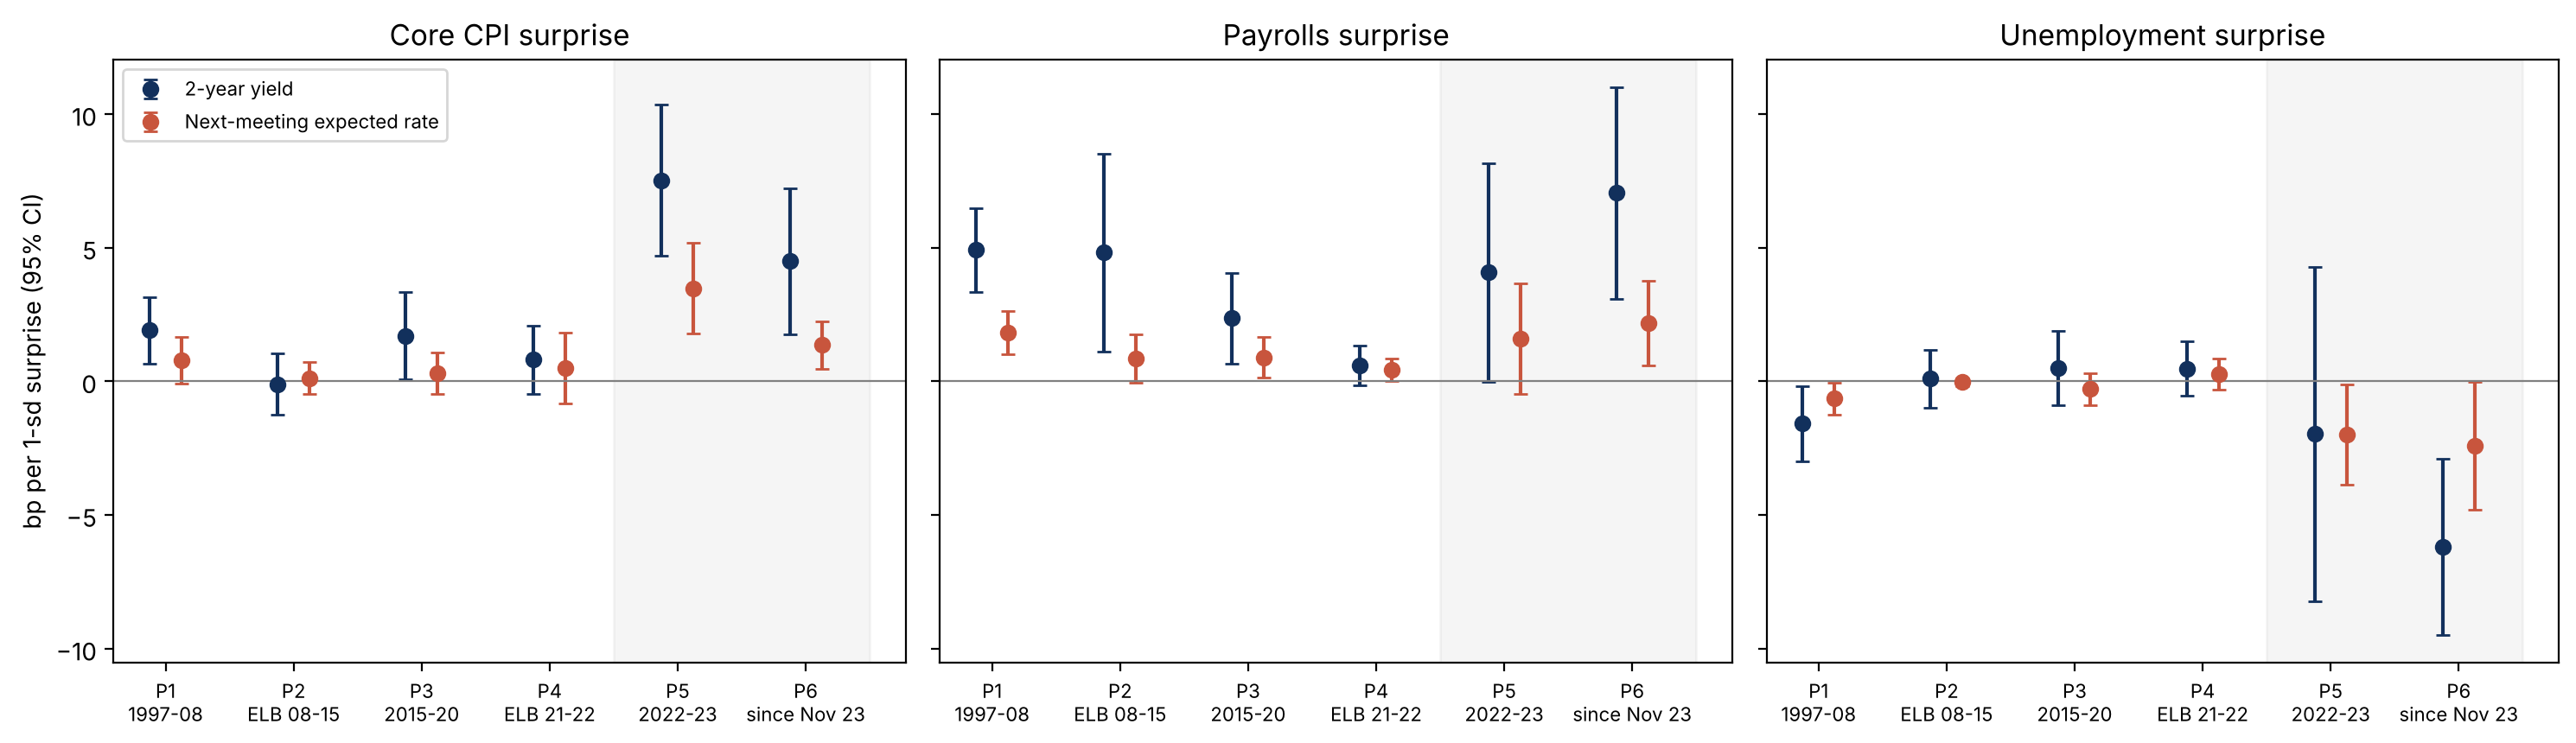

In [12]:
coefs = pd.concat([raw_2y, raw_next])
labels = {'d2y': '2-year yield', 'dnext': 'Next-meeting expected rate'}
titles = {'CORE_CPI_MOM': 'Core CPI surprise', 'NFP': 'Payrolls surprise', 'UNEMPLOYMENT': 'Unemployment surprise'}
short = ['P1\n1997-08', 'P2\nELB 08-15', 'P3\n2015-20', 'P4\nELB 21-22', 'P5\n2022-23', 'P6\nsince Nov 23']
xpos = np.arange(len(PHASES))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, v in zip(axes, X_MAIN):
    for k, (dep, col) in enumerate([('d2y', '#12305C'), ('dnext', '#C8553D')]):
        c = coefs[(coefs['dep'] == dep) & (coefs['var'] == v)]
        ax.errorbar(xpos + (k - 0.5) * 0.25, c['coef'], yerr=1.96 * c['se'], fmt='o', color=col,
                    capsize=3, label=labels[dep])
    ax.axhline(0, color='grey', lw=0.8)
    ax.axvspan(3.5, 5.5, color='grey', alpha=0.08)
    ax.set_xticks(xpos)
    ax.set_xticklabels(short, fontsize=8)
    ax.set_title(titles[v])
axes[0].set_ylabel('bp per 1-sd surprise (95% CI)')
axes[0].legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.savefig(FIG / 'mission5_coefficients_by_phase.png', dpi=300, bbox_inches='tight')
plt.show()

## 10. Recent releases (descriptive, not an estimate)

Releases since June 2026 with the surprise and the daily changes. This replaces the press figures of Table 1 of the first report with Bloomberg data. Too few observations to estimate anything for the current Chair alone.

In [13]:
recent = (macro[(macro['release_date'] >= '2026-06-01') & macro['indicator'].isin(X_MAIN)]
          .merge(panel[['d2y', 'dnext']], left_on='release_date', right_index=True)
          [['release_date', 'indicator', 'ref_period', 'actual', 'survey_median', 'surprise', 'surprise_std', 'd2y', 'dnext']]
          .sort_values(['release_date', 'indicator']))
recent.to_csv(OUT / 'recent_releases_2026.csv', index=False)
recent.round({'surprise': 2, 'surprise_std': 2, 'd2y': 2, 'dnext': 2})

,release_date,indicator,ref_period,actual,survey_median,surprise,surprise_std,d2y,dnext
1063,2026-06-05,NFP,2026-05-31,172.0,86.0,86.0,0.82,10.39,1.15
1418,2026-06-05,UNEMPLOYMENT,2026-05-31,4.3,4.3,0.0,0.00,10.39,1.15
349,2026-06-10,CORE_CPI_MOM,2026-05-31,0.2,0.3,-0.1,-0.96,2.52,-0.58
1064,2026-07-02,NFP,2026-06-30,57.0,113.0,-56.0,-0.53,-3.73,-2.50
1419,2026-07-02,UNEMPLOYMENT,2026-06-30,4.2,4.3,-0.1,-0.70,-3.73,-2.50
350,2026-07-14,CORE_CPI_MOM,2026-06-30,0.0,0.2,-0.2,-1.92,-8.81,-6.50
1065,2026-08-07,NFP,2026-07-31,-23.0,88.0,-111.0,-1.06,-5.02,-3.21
1420,2026-08-07,UNEMPLOYMENT,2026-07-31,4.1,4.2,-0.1,-0.70,-5.02,-3.21
351,2026-08-12,CORE_CPI_MOM,2026-07-31,0.2,0.2,0.0,0.00,-1.27,-2.14
1066,2026-09-04,NFP,2026-08-31,162.0,56.0,106.0,1.01,3.01,2.68


## 11. Summary and limits

**Summary** (see the tables above for the exact figures)

* The repaired file gives about 355 releases per indicator from 1997 to November 2026.
* The 2-year yield reacts to payroll surprises in every phase except the second lower-bound phase, and to core CPI surprises in every phase away from the lower bound. The expected rate for the next meeting reacts much less (smaller coefficients and R²); its large reaction to core CPI appears only after 2022. This is the pattern described by Healy and Jia.
* In March 2022–October 2023 the raw core CPI coefficient on the next-meeting rate is of the same order as the one reported by Healy and Jia.
* The pooled test shows a significant increase in sensitivity after March 2022: at the 1–5% level for all three surprises on the 2-year yield, and for core CPI and unemployment on the next-meeting rate (payrolls only at 10%).
* Since November 2023 the sensitivity to inflation surprises is lower than in 2022–2023 but remains well above pre-2020 levels, and the reaction to labour-market surprises is the strongest in the sample.

**Limits**

* Daily changes: other news on the same day enters the dependent variable (intraday futures data would allow a 30-minute window).
* Futures-implied rates include risk premia; the results describe market-implied expectations.
* The FOMC event file contains only three unscheduled meetings (2008, March 2020); unscheduled moves before 2008 (e.g. 2001) are not flagged.
* The P4 and P5 phases contain only 27 to 40 releases.